The original model we were working with was 
\begin{align}
\frac{df_1}{dt}&=-\beta f_1c_1-\beta f_1^2+\kappa c_1 -\rho f_1 +\rho f_2\\
\frac{dc_1}{dt}&=\beta f_1c_1+\beta f_1^2-\kappa c_1\\
\frac{df_2}{dt}&=-\beta f_2c_2-\beta f_2^2+\kappa c_2 +\rho f_1 -\rho f_2\\
\frac{dc_2}{dt}&=\beta f_2c_2+\beta f_2^2-\kappa c_2.
\end{align}

We will compare this to a few models with different nonlinearities in plasmid binding, and the linear model. Later we will add in replication and compare the asymmetry from the replication models to Jayson's simulations.


The differences in the binding terms are as follows:

Nonlin A: $-\beta f_1c_1-\beta f_1^2$

Nonlin B: $-\beta f_1-\beta f_1^2$

Nonlin C: $-\beta f_1*N-\beta f_1^2$

Linear: $-\beta N/2 f_1$


Model A is slow compared to linear. Model C is approximately the same as linear. Model B is faster than linear. All three equilibrate slower than cell cycle time, so our argument about asymmetry and cell division time still makes sense regardless of which model is closest. 

It turns out that the linear model is close to Jayson's simulation. 


In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import pandas as pd

In [2]:

# Parameters
beta = 0.015*1
#beta = .17
kappa = 0.08*1
rho   = 0.13*1

#replication parameters
#tau=40
#k_tr=2.84 #changes with \tau
#K=14.5/1.26 #changes with \tau
#V=1.2 #changes with \tau, and currently set to halfway between V0=.8 and 2V0=1.6 for \tau=40
#V0=.8

#tau=30
#k_tr=2.17
#K=15.8/1.26
#V=1.8 #halfway between V0=1.2 and 2V0=2.4 for \tau=30
#V0=1.2

tau=24
k_tr=1.49
K=15.2/1.26
V=2.4 #halfway between V0=1.6 and 2V0=3.2 for \tau=30
V0=1.6


s0=0.034
n=2.56

N=25

# nonlinear system A
def odesA(t, y, beta, kappa, rho):
    f1, c1, f2, c2 = y
    
    df1dt = -beta * f1 * c1 - beta * f1**2 + kappa * c1 - rho * f1 + rho * f2
    dc1dt =  beta * f1 * c1 + beta * f1**2 - kappa * c1
    df2dt = -beta * f2 * c2 - beta * f2**2 + kappa * c2 + rho * f1 - rho * f2
    dc2dt =  beta * f2 * c2 + beta * f2**2 - kappa * c2
    
    return [df1dt, dc1dt, df2dt, dc2dt]

# nonlinear system B
def odesB(t, y, beta, kappa, rho):
    f1, c1, f2, c2 = y
    
    df1dt = -beta * f1 *1 - beta * f1**2 + kappa * c1 - rho * f1 + rho * f2
    dc1dt =  beta * f1 *1 + beta * f1**2 - kappa * c1
    df2dt = -beta * f2 *1 - beta * f2**2 + kappa * c2 + rho * f1 - rho * f2
    dc2dt =  beta * f2 *1 + beta * f2**2 - kappa * c2
    
    return [df1dt, dc1dt, df2dt, dc2dt]

# nonlinear system C
def odesC(t, y, beta, kappa, rho):
    f1, c1, f2, c2 = y
    
    df1dt =  -beta*f1*N - beta * f1**2 + kappa * c1 - rho * f1 + rho * f2
    dc1dt =   beta*f1*N + beta * f1**2 - kappa * c1
    df2dt =  -beta*f2*N - beta * f2**2 + kappa * c2 + rho * f1 - rho * f2
    dc2dt =   beta*f2*N + beta * f2**2 - kappa * c2
    
    return [df1dt, dc1dt, df2dt, dc2dt]

# linear system system
def odes_lin(t, y, beta, kappa, rho):
    f1, c1, f2, c2 = y
    
    dff1dt = -beta * N/2 * f1 + kappa * c1 - rho * f1 + rho * f2
    dfc1dt =  beta * N/2 * f1 - kappa * c1
    dff2dt = -beta * N/2 * f2 + kappa * c2 + rho * f1 - rho * f2
    dfc2dt =  beta * N/2 * f2 - kappa * c2
 
    
    return [dff1dt, dfc1dt, dff2dt, dfc2dt]

###### Replication models
def odeA_rep(t, y, beta, kappa, rho):
    f1, c1, f2, c2 = y
    
    df1dt = -beta * f1 * c1 - beta * f1**2 + kappa * c1 - rho * f1 + rho * f2 + k_tr * (f1 + c1) / (1 + (K * (f1+c1+f2+c2)) / (s0 * 602 * n * V))**n#+ k_tr/((1+(K/(s0*n*V*602.2))*(f1+c1+f2+c2))**n)*(f1+c1)
    dc1dt =  beta * f1 * c1 + beta * f1**2 - kappa * c1

    df2dt = -beta * f2 * c2 - beta * f2**2 + kappa * c2 + rho * f1 - rho * f2 + k_tr * (f2 + c2) / (1 + (K * (f1+c1+f2+c2)) / (s0 * 602 * n * V))**n#+ k_tr/((1+(K/(s0*n*V*602.2))*(f1+c1+f2+c2))**n)*(f2+c2)
    dc2dt =  beta * f2 * c2 + beta * f2**2 - kappa * c2
    return [df1dt, dc1dt, df2dt, dc2dt]

def odeB_rep(t, y, beta, kappa, rho):
    f1, c1, f2, c2 = y
    
    df1dt = -beta * f1 *1  - beta * f1**2 + kappa * c1 - rho * f1 + rho * f2 + k_tr * (f1 + c1) / (1 + (K * (f1+c1+f2+c2)) / (s0 * 602 * n * V))**n#+ k_tr/((1+(K/(s0*n*V*602.2))*(f1+c1+f2+c2))**n)*(f1+c1)
    dc1dt =  beta * f1 *1+ beta * f1**2 - kappa * c1
    df2dt = -beta * f2 *1 - beta * f2**2 + kappa * c2 + rho * f1 - rho * f2 + k_tr * (f2 + c2) / (1 + (K * (f1+c1+f2+c2)) / (s0 * 602 * n * V))**n#+ k_tr/((1+(K/(s0*n*V*602.2))*(f1+c1+f2+c2))**n)*(f2+c2)
    dc2dt =  beta * f2 *1 + beta * f2**2 - kappa * c2
    return [df1dt, dc1dt, df2dt, dc2dt]

def odeC_rep(t, y, beta, kappa, rho):
    f1, c1, f2, c2 = y
    
    df1dt = -beta * f1 * N - beta * f1**2 + kappa * c1 - rho * f1 + rho * f2 + k_tr * (f1 + c1) / (1 + (K * (f1+c1+f2+c2)) / (s0 * 602 * n * V))**n#+ k_tr/((1+(K/(s0*n*V*602.2))*(f1+c1+f2+c2))**n)*(f1+c1)
    dc1dt =  beta * f1 * N + beta * f1**2 - kappa * c1

    df2dt = -beta * f2 * N - beta * f2**2 + kappa * c2 + rho * f1 - rho * f2 + k_tr * (f2 + c2) / (1 + (K * (f1+c1+f2+c2)) / (s0 * 602 * n * V))**n#+ k_tr/((1+(K/(s0*n*V*602.2))*(f1+c1+f2+c2))**n)*(f2+c2)
    dc2dt =  beta * f2 * N + beta * f2**2 - kappa * c2
    return [df1dt, dc1dt, df2dt, dc2dt]

def ode_lin_rep(t, y, beta, kappa, rho):
    f1, c1, f2, c2 = y
    
    df1dt = -beta * N*(3/4) * f1 + kappa * c1 - rho * f1 + rho * f2 + k_tr * (f1 + c1) / (1 + (K * (f1+c1+f2+c2)) / (s0 * 602 * n * V))**n#+ k_tr/((1+(K/(s0*n*V*602.2))*(f1+c1+f2+c2))**n)*(f1+c1)
    dc1dt =  beta * N*(3/4) * f1 - kappa * c1

    df2dt = -beta * N*(3/4) * f2 + kappa * c2 + rho * f1 - rho * f2 + k_tr * (f2 + c2) / (1 + (K * (f1+c1+f2+c2)) / (s0 * 602 * n * V))**n#+ k_tr/((1+(K/(s0*n*V*602.2))*(f1+c1+f2+c2))**n)*(f2+c2)
    dc2dt =  beta * N*(3/4) * f2 - kappa * c2
    return [df1dt, dc1dt, df2dt, dc2dt]


Solve all the  non-replication systems:

In [3]:
# Initial conditions
y0 = [42, 0, 0, 0]  # f1, c1, f2, c2
N = y0[0]+y0[1]

# Time span
t_span = (0, 5000)
t_eval = np.linspace(t_span[0], t_span[1], 10000)

# Solve ODE systems no replication
solA = solve_ivp(odesA, t_span, y0, args=(beta, kappa, rho), t_eval=t_eval, method='BDF')
solB = solve_ivp(odesB, t_span, y0, args=(beta, kappa, rho), t_eval=t_eval, method='BDF')
solC = solve_ivp(odesC, t_span, y0, args=(beta, kappa, rho), t_eval=t_eval, method='BDF')
sol_lin = solve_ivp(odes_lin, t_span, y0, args=(beta, kappa, rho), t_eval=t_eval, method='BDF')



Plot the four trajectories for each of the four systems, no replication

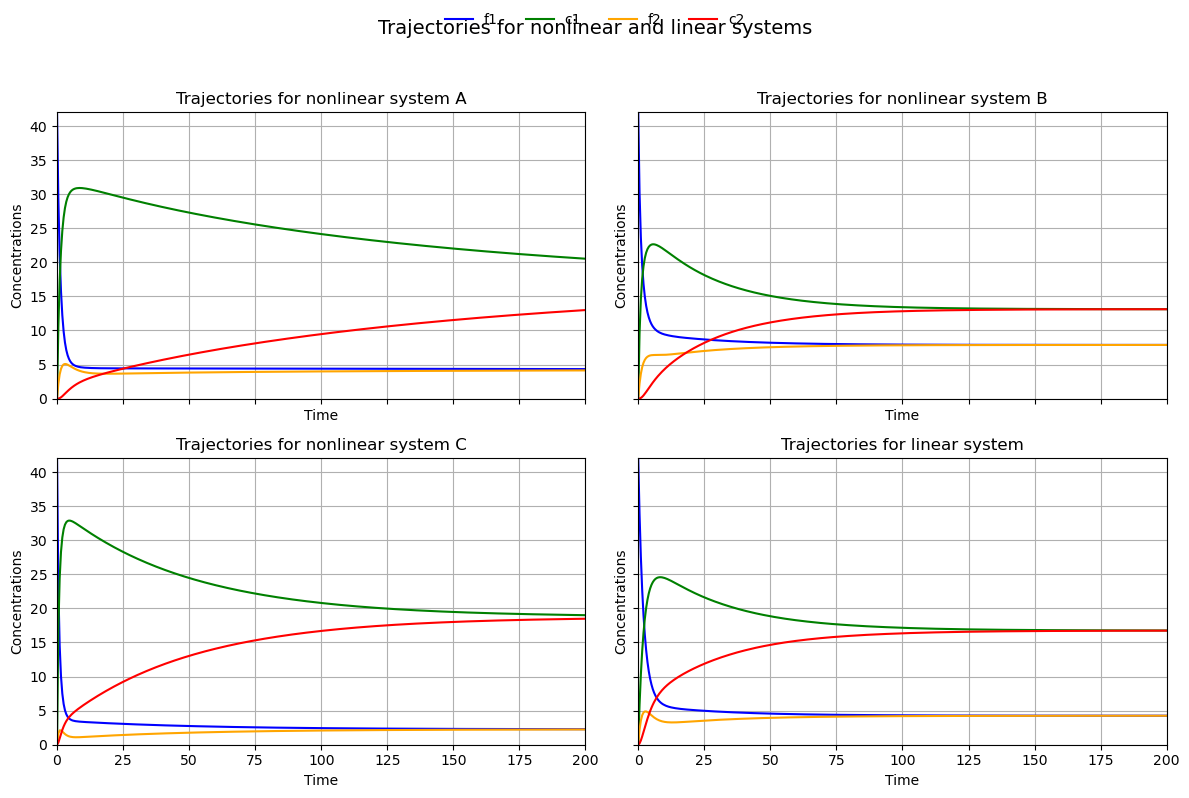

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
axes = axes.flatten()  # make it easier to iterate

systems = [
    (solA, "Trajectories for nonlinear system A"),
    (solB, "Trajectories for nonlinear system B"),
    (solC, "Trajectories for nonlinear system C"),
    (sol_lin, "Trajectories for linear system"),
]

colors = ['blue', 'green', 'orange', 'red']
labels = ['f1', 'c1', 'f2', 'c2']

for ax, (sol, title) in zip(axes, systems):
    for i, (label, color) in enumerate(zip(labels, colors)):
        ax.plot(sol.t, sol.y[i], label=label, color=color)
    ax.set_title(title)
    ax.set_xlabel("Time")
    ax.set_ylabel("Concentrations")
    ax.grid()
    ax.set_xlim(0, 200)
    ax.set_ylim(0, 42)

# Add one legend shared across subplots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False)

fig.suptitle("Trajectories for nonlinear and linear systems", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])  # make room for the shared legend and title
plt.show()


Plot delta f and delta N, linear model:

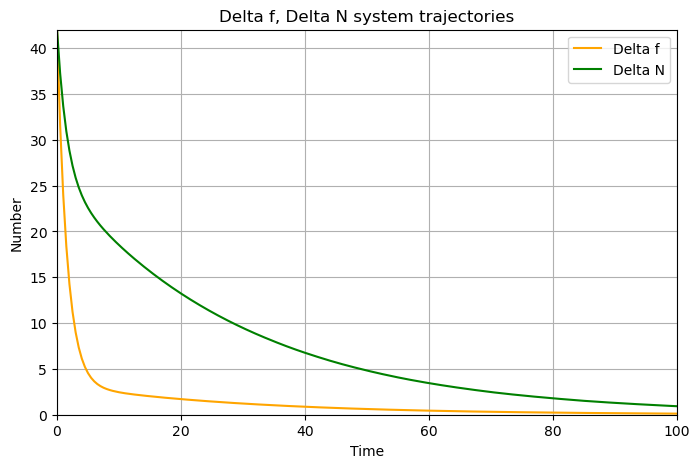

In [5]:
sol_lin = solve_ivp(odes_lin, t_span, y0, args=(beta, kappa, rho), t_eval=t_eval, method='BDF')


plt.figure(figsize=(8,5))


plt.plot(sol_lin.t,( (sol_lin.y[0])-(sol_lin.y[2])), label='Delta f', color='orange')
plt.plot(sol_lin.t, (sol_lin.y[0]+sol_lin.y[1])-(sol_lin.y[2]+sol_lin.y[3]), label='Delta N', color='green')
#plt.hlines(1,0,200)

plt.xlabel("Time")
plt.ylabel("Number")
plt.legend()
plt.title("Delta f, Delta N system trajectories")
plt.grid()
plt.ylim(0,42)
plt.xlim(0,100)
plt.show()

Next I will do sensitivity analysis for $\Delta f$ and $\Delta N$ for the linear model. I will vary $\kappa$ and $\beta$ both between 3 different values to make a 3 by 3 grid of figures, and I will do this for 3 different values of $\rho$. I will start with multiplying each parameter by .5, 1, and 2, and then if the curves seem insensitive to those changes I will see how far I can push things.

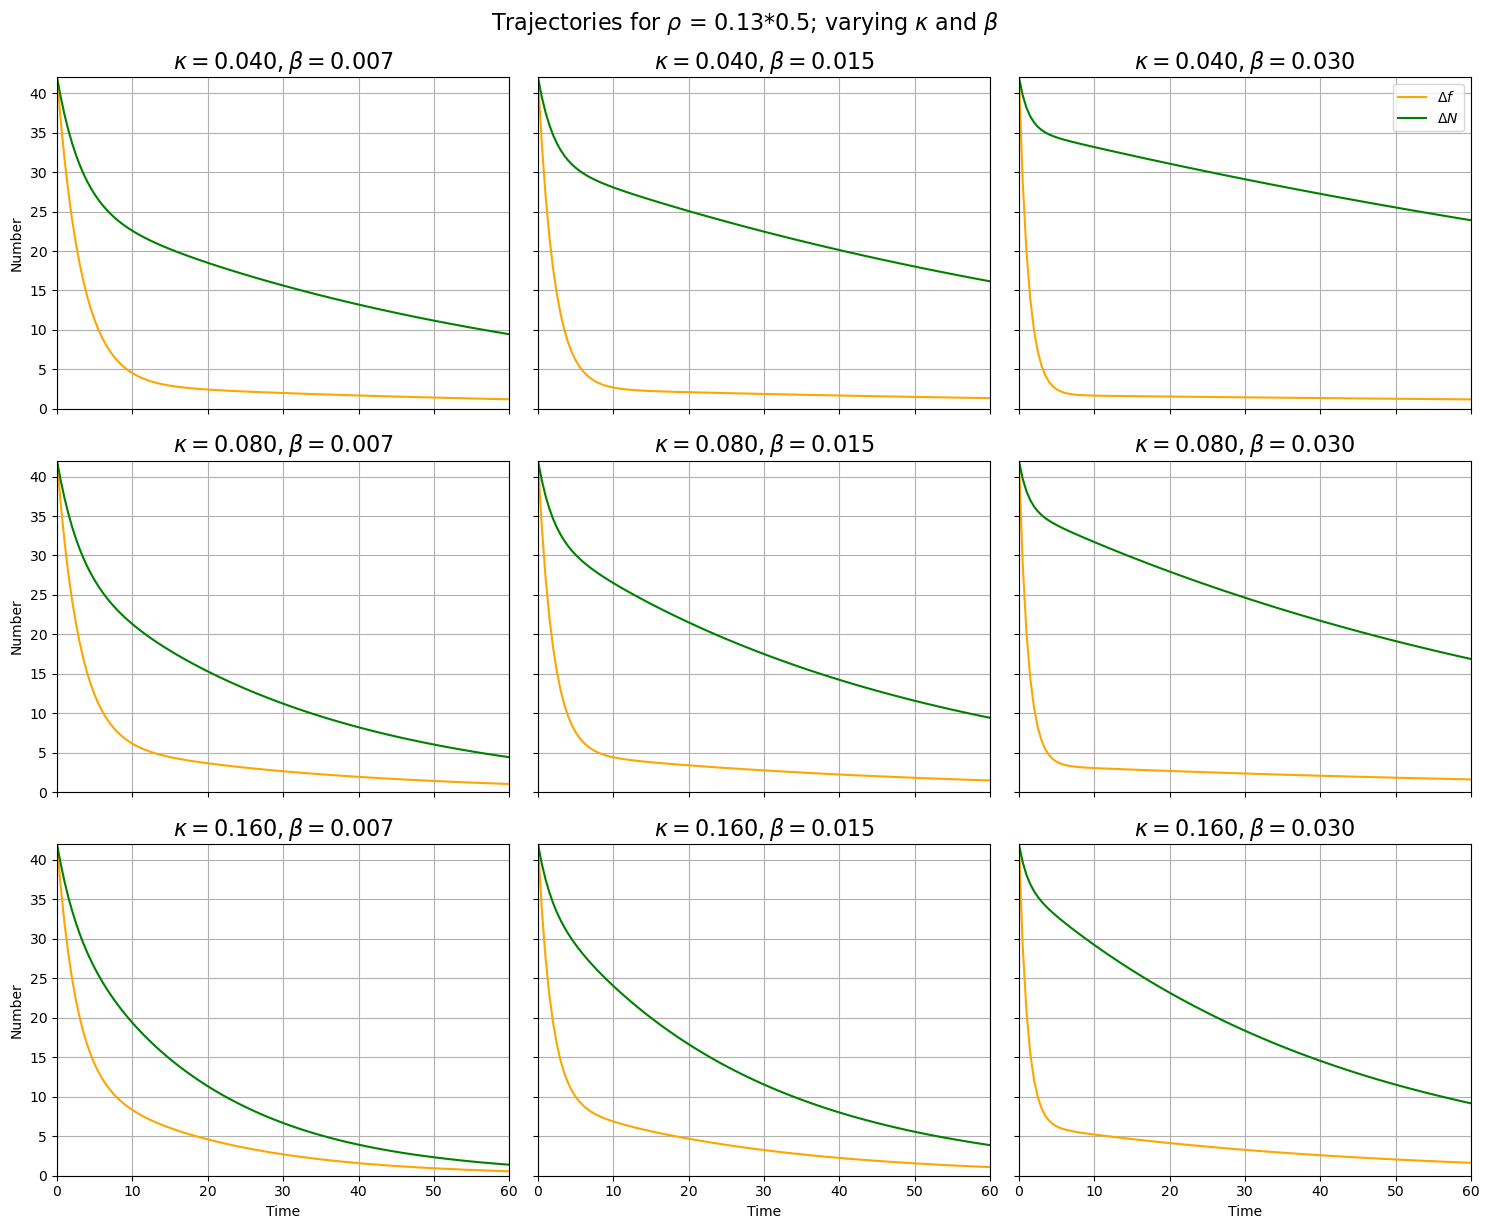

In [6]:

rho_val=.5 #can adjust to see effects of rho
rho=.13*rho_val

# Lists for variation
multipliers = [0.5, 1.0, 2.0]
kappa_vals = [m * kappa for m in multipliers]
beta_vals = [m * beta for m in multipliers]

# Create the 3x3 grid
fig, axes = plt.subplots(3, 3, figsize=(15, 12), sharex=True, sharey=True)

for i, k_val in enumerate(kappa_vals):
    for j, b_val in enumerate(beta_vals):
        # Current subplot
        ax = axes[i, j]
        
        # Solve the IVP with current kappa and beta
        # Note: maintaining the order (beta, kappa, rho) from your original snippet
        solution = solve_ivp(odes_lin, t_span, y0, args=(b_val, k_val, rho), 
                            t_eval=t_eval, method='BDF')
        
        # Plotting the trajectories
        ax.plot(solution.t, (solution.y[0] - solution.y[2]), 
                label='$\Delta f$', color='orange')
        ax.plot(solution.t, (solution.y[0] + solution.y[1]) - (solution.y[2] + solution.y[3]), 
                label='$\Delta N$', color='green')
        
        # Subplot formatting
        ax.set_title(f"$\kappa={k_val:.3f}, \\beta={b_val:.3f}$", fontsize=16)
        ax.grid(True)
        ax.set_ylim(0, 42)
        ax.set_xlim(0, 60)
        
        # Add legend only to one plot to avoid clutter, or all if preferred
        if i == 0 and j == 2:
            ax.legend()

# Add global labels
for ax in axes[-1, :]:
    ax.set_xlabel("Time")
for ax in axes[:, 0]:
    ax.set_ylabel("Number")

plt.tight_layout()
plt.suptitle("Trajectories for $\\rho$ = 0.13*" + str(rho_val) + "; varying $\kappa$ and $\\beta$", y=1.02, fontsize=16)
plt.show()

Plot asymmetry, (f1+c1)-(f2+c2), for all 4 models on same axes. 

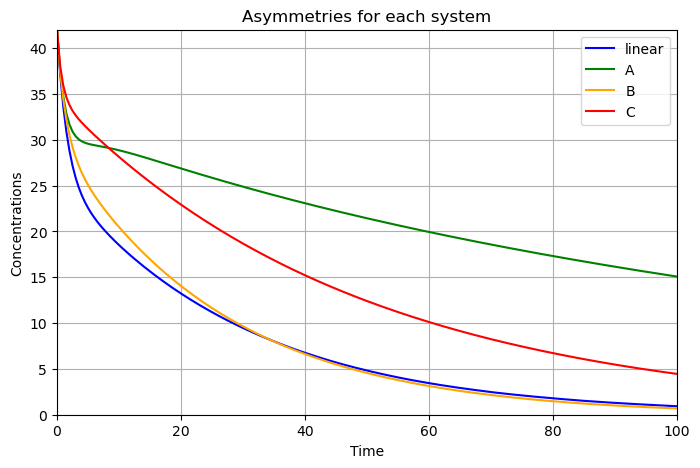

In [7]:
plt.figure(figsize=(8,5))
plt.plot(sol_lin.t, (sol_lin.y[0]+sol_lin.y[1])-(sol_lin.y[2]+sol_lin.y[3]), label='linear', color='blue')
plt.plot(solA.t, (solA.y[0]+solA.y[1])-(solA.y[2]+solA.y[3]), label='A', color='green')
plt.plot(solB.t, (solB.y[0]+solB.y[1])-(solB.y[2]+solB.y[3]), label='B', color='orange')
plt.plot(solB.t, (solC.y[0]+solC.y[1])-(solC.y[2]+solC.y[3]), label='C', color='red')



plt.xlabel("Time")
plt.ylabel("Concentrations")
plt.legend()
plt.title("Asymmetries for each system")
plt.grid()
plt.ylim(0,42)
plt.xlim(0,100)
plt.show()

Now compare with Jayson's model. First, set up his simulation:

In [8]:
import numpy as np
import warnings
import pickle
import time

beta = 0.015*1
#beta = .17
kappa = 0.08*1
rho   = 0.13*1

##################################################
class cell:
    def __init__(self,index,init_clusters,parent,birth,tau):
        '''Initializes cell attributes
        param:: index: cell index
        param:: clusters: count of n-clusters
        param:: x: plasmid trajectory in time 
        param:: t: time stamps for x
        param:: parent: parent cell
        param:: birth: birth time
        return:: None
        '''
        self.index=index
        self.init_clusters=init_clusters
        self.fin_clusters=[]
        self.x = []
        self.t = []
        self.parent = parent
        self.birth = birth
        self.div = birth+tau+np.random.normal(0,1)

def find_tot_plasmids(y1,y2,max_size):
    y1[0]+=y1[1]   #because of plasmid shedding y[1] may have a nonzero value, we transfer this to y[0].
    y2[0]+=y2[1]
    y1[1]=y1[0]
    y2[1]=y2[0]
    y_tot1 = np.dot(np.arange(1,max_size),y1[1:max_size])
    y_tot2 = np.dot(np.arange(1,max_size),y2[1:max_size])            
    y_tot = y_tot1+y_tot2
    y1[1]=0
    y2[1]=0
    return y1,y2,y_tot1,y_tot2,y_tot 

def pop_check(cells,T):
    b_filter = [x for x in cells if x.t[0] <= T]
    d_filter = [x for x in b_filter if x.t[-1] >T]
    return d_filter #N_pop

def hazards(y,c_idx,num_reax,N,beta,gamma,sigma,max_size,t_f,y_totp,y_tot): 
    a = np.zeros(num_reax)                                     #reaction hazards 
    v = np.zeros([num_reax,max_size])                           #reaction vectors    
    #V = V0*np.exp(mu*t_f)
    a[0]= 1 #(k_tr*y_totp)/(1+K*y_tot/(s0*6.022e2*n*V))**n    #not needed since computation of reaction time is different 
    v[0,0] = 1
    a[1] = 0.5*beta*y[0]*(y[0]-1)
    v[1,0] = -2
    v[1,2] = 1
    
    if N>1:
        species_idx =np.zeros([2,num_reax])
        count=1
        for i in np.arange(1,N):   #plasmid recruitment
            count+=1
            a[count] = beta*y[0]*y[c_idx[i]]
            species_idx[:,count] = np.array([c_idx[i],0])
        rec_count=count
                
        for i in np.arange(1,N):   #cluster combination
            for j in np.arange(i,N):
                count+=1
                if i==j:
                    a[count] = 0.5*gamma*y[c_idx[i]]*(y[c_idx[j]]-1)
                else:
                    a[count] = gamma*y[c_idx[i]]*y[c_idx[j]]
                species_idx[:,count] = [c_idx[i],c_idx[j]]
        cluster_count = count
            
        for i in np.arange(1,N): #plasmid shedding
            count+=1
            a[count] = sigma*y[c_idx[i]]*c_idx[i]
            species_idx[:,count] = np.array([c_idx[i],0])
                    
        for i in range(len(a)): #reaction vectors
            if i==0:                         #plasmid replication
                v[i,0] = 1
            elif i==1:                       #plasmid duplex formation
                v[i,0] = -2
                v[i,2] = 1
            elif (2<=i and i<=rec_count):    #plasmid recruitment to a cluster
                v[i,0] = -1
                v[i,int(species_idx[0,i])] = -1
                v[i,int(species_idx[0,i])+1] = 1
            elif (i>rec_count and i<=cluster_count):   #cluster combination
                if (int(species_idx[0,i])==int(species_idx[1,i]) and y[int(species_idx[1,i])]>1 ):
                    v[i,int(species_idx[0,i])] = -2
                    v[i,int(np.sum(species_idx[:,i]))] = 1
                elif not(int(species_idx[0,i])==int(species_idx[1,i])):
                    v[i,int(species_idx[0,i])] = -1
                    v[i,int(species_idx[1,i])] = -1
                    v[i,int(np.sum(species_idx[:,i]))] = 1
            else:  #plasmid shedding         
                if int(species_idx[0,i]) == 2:   
                    v[i,0] = 2
                    v[i,int(species_idx[0,i])] = -1 
                else:
                    v[i,0] = 1
                    v[i,int(species_idx[0,i])] = -1
                    v[i,int(species_idx[0,i])-1] = 1 
    return a,v

def time_approx(s,xi,y_tot,eps):
    D=k_tr*xi
    V=V0*np.exp(mu*s)
    C=K*y_tot/(s0*6.022e2*n)
    a_prime = (mu*n*D*C/V)*(1+C/V)**(-n-1)
    a = D/(1+C/V)**n 
    return (-a+np.sqrt(a**2-2*a_prime*np.log(eps)))/a_prime

def ssa_vol(y0,x0,tau,beta,gamma,sigma,max_size):
    y=y0               #plasmid cluster count; y[0]=x[0], y[1]=0, y[i] = number of cluster of size i     
    x=[x0]
    t_x = [0]
    t_y=0             #reaction time 
    y_tot1=x0
    y_tot2 = 0
    clust = [y]
    ty = []
    y1 = y[:max_size]
    y2 = y[max_size:2*max_size] 
    y_tot=y_tot1+y_tot2
    while t_y<tau:
        #print('########## new reaction')
        ############################### pole 1 ##################################    
        if y_tot1>0:
            dummy = y1[0]                                               
            y1[0] = 1
            c_idx1 = np.where(y1>0)[0]                                  #indices of species with non-zero state except possibly free plasmids
            y1[0] = dummy
            N1 = len(c_idx1)                                            #number of non-zero species
            num_reax1 = N1+1+int(((N1-1)**2-N1+1)/2)+2*(N1-1)           #possible number of reactions given the system state 
            a1,v1 = hazards(y1,c_idx1,num_reax1,N1,beta,gamma,sigma,max_size,t_y,y_tot1,y_tot)     
        else:
            num_reax1 = 1
            a1 = [0]
            v1 = np.zeros([1,max_size])
        
        ############################### pole 2 ##################################
        if y_tot2>0:
            dummy = y2[0]
            y2[0]=1
            c_idx2 = np.where(y2>0)[0]                                  
            y2[0]=dummy
            N2 = len(c_idx2)
            num_reax2 = N2+1+int(((N2-1)**2-N2+1)/2)+2*(N2-1)  
            a2,v2 = hazards(y2,c_idx2,num_reax2,N2,beta,gamma,sigma,max_size,t_y,y_tot2,y_tot)
            a = np.append(a1,a2,axis=0)
       
        else:
            num_reax2 = 1
            a2 = [0]
            a = np.append(a1,a2,axis=0)
            v2 = np.zeros([1,max_size])
            
        a = np.append(a,[rho*y1[0],rho*y2[0]])
        epsilon=np.random.uniform(0,1,len(a))
        t_j  = np.zeros(num_reax1+num_reax2+2)
        
        for i in range(len(a)):
            if a[i]==0:
                t_j[i] = np.inf
            else:
                if i == 0: #replication in pole 1
                    t_j[i] = time_approx(t_y,y_tot1,y_tot,epsilon[i])
                elif i == num_reax1:  #replication in pole 2
                    t_j[i] = time_approx(t_y,y_tot2,y_tot,epsilon[i])
                else:
                    t_j[i] = -np.log(epsilon[i])/a[i]
        j=np.argmin(t_j)
        
        if (j==num_reax1+num_reax2): #plasmid transfer pole 1 to 2
            y2[0]+=1
            y1[0]-=1
        elif (j==num_reax1+num_reax2+1): #plasmid transfer pole 2 to 1
            y2[0]-=1
            y1[0]+=1
        elif (num_reax1<=j and j<num_reax1+num_reax2):
            y2+=v2[j-num_reax1,:]  
        else:
            y1+=v1[j,:]    
        y1,y2,y_tot1,y_tot2,y_tot = find_tot_plasmids(y1,y2,max_size)
        if (j==0 or j==num_reax1):
            x= np.append(x,y_tot)
            t_x =np.append(t_x,[t_y])
        t_y+=t_j[j]
        ty =np.append(ty,[t_y]) 
        clust = np.vstack((clust,np.append(y1,y2,axis=0)))
    y = np.append(y1,y2,axis=0)
    #return y1, y2, y, x, t_x, clust, ty
    return y1, y2, y, np.array(x), np.array(t_x, dtype=float), clust, ty
    #return y,x,t_x,clust,ty

def sim_cells(current,beta,gamma,sigma,max_size):
    y0 = current.init_clusters
    y0[1]=y0[0]
    x0 = np.dot(np.arange(1,max_size),y0[1:max_size])
    y0[1]=0 
    if x0>0:
        yy1, yy2, yy,xx,tt,clust,ty = ssa_vol(y0,x0,current.div-current.birth,beta,gamma,sigma,max_size)
    else:
        yy = y0
        xx = np.array([0,0])
        tt = np.array([0,current.div-current.birth])
        clust = np.zeros(max_size)
        ty = np.array([0,current.div-current.birth])
    return yy1, yy2, yy,xx,tt,clust,ty

def lineage_sim(c,tau,beta,gamma,sigma,max_size):
    Line=[]
    current_cell = c 
    N=0
    length = 1
    status =1
    while status == 1:
        #print('############## new cell ##############')
        zz0 = np.copy(current_cell.init_clusters) 
        yy1, yy2, yy,xx,tt,clust,ty= sim_cells(current_cell,beta,gamma,sigma,max_size)
        current_cell.fin_clusters = yy
        current_cell.x = xx
        current_cell.t = tt+current_cell.birth  
        current_cell.init_clusters = zz0
        
        Line.extend([current_cell])

        
        if np.random.uniform(0,1)<0.5:
            daughter = cell(N+1,np.append(yy[:max_size],np.zeros(max_size)),current_cell.index,current_cell.t[-1],tau)
        else:
            daughter = cell(N+1,np.append(yy[max_size:],np.zeros(max_size)),current_cell.index,current_cell.t[-1],tau)
        x0 = np.dot(np.arange(1,max_size),daughter.init_clusters[1:max_size])+daughter.init_clusters[0]
        
        if current_cell.x[-1]==x0 or x0==0 or len(Line)==10: #change length of lineage. Was 10, if making replication 0 set to 1
            status = 0
        else:
            length+=1
            status = 1
            current_cell = daughter
            #print(current_cell.init_clusters)
            N+=1
        
        if len(Line)%50==0:
            print(len(Line))
    return yy1, yy2, Line,length,clust,ty

##################################################
n =  2.56  #4.84 #2.56 #8.85
s0 = 0.034 #0.06 #0.034 #0.08  
#tau = 30             #30-min doubling time
#tau = 40
tau = 24

#k_tr = 2.17  #change with tau
#k_tr = 2.84
k_tr = 1.49

#K = 15.8/1.26  #change with tau
#K = 14.5/1.26
K = 15.2/1.26
mu = np.log(2)/tau #parameters are for tau=30

#V0 = 1.2 #change with tau
#V0 = 0.8
V0 = 1.6
rho = 0.13*1

x0=25#42          #number of plasmids in the initial cell
max_size=200   #total number of possible clusters, can be increased to accomodate larger sims

true_beta = 0.015*1
#true_beta = 0.17
true_sigma = 0.08*1
true_gamm = 0.05*1


########## Simulate many trajectories and find mean and std dev

repeats = 400
t_grid = np.linspace(0, tau, 300)  # choose resolution for common time grid

per_x1, per_x2, per_c1, per_c2 = [], [], [], []

def safe_interp(vals, times, t_grid):
    """
    Interpolate `vals` at `times` onto `t_grid` robustly:
      - trims/pads to min length
      - returns constant curve if no data
      - enforces strictly increasing times (tiny eps)
    """
    vals = np.array(vals, dtype=float)
    times = np.array(times, dtype=float)

    # If either is empty, return a constant (try to use vals[0] or 0)
    if len(vals) == 0 or len(times) == 0:
        const_val = vals[0] if len(vals) > 0 else 0.0
        return np.full_like(t_grid, const_val, dtype=float)

    # Align lengths (common practical mismatches are off-by-one)
    if len(times) == len(vals):
        pass
    elif len(times) == len(vals) + 1:
        # times has extra initial or final entry -> drop first element
        times = times[1:]
    elif len(vals) == len(times) + 1:
        # values has extra -> trim values
        vals = vals[: len(times)]
    else:
        # fallback: trim to min length
        m = min(len(times), len(vals))
        times = times[:m]
        vals = vals[:m]

    # ensure strictly increasing times (add tiny eps to duplicates or ties)
    if len(times) > 1:
        for i in range(1, len(times)):
            if times[i] <= times[i - 1]:
                times[i] = times[i - 1] + 1e-12

    # Finally interpolate
    return np.interp(t_grid, times, vals)


for k in range(repeats):
    # run one lineage simulation (uses your existing lineage_sim and cell classes)
    y0 = np.zeros(2 * max_size)
    y0[0] = x0
    c = cell(0, y0, [], 0, tau)
    yy1, yy2, Line, length, clust, ty = lineage_sim(c, tau, true_beta, true_gamm, true_sigma, max_size)

    # Build per-event lists from clust (entries 1..end)
    # free plasmids in pole1 and pole2
    x1_vals = [clust[i][0] for i in range(1, len(clust))]
    x2_vals = [clust[i][max_size] for i in range(1, len(clust))]

    # clustered plasmids totals per pole
    pole1 = [clust[i][:max_size] for i in range(1, len(clust))]
    pole2 = [clust[i][max_size:] for i in range(1, len(clust))]
    c1_vals = [np.dot(np.arange(0, max_size), p) for p in pole1]
    c2_vals = [np.dot(np.arange(0, max_size), p) for p in pole2]

    # Interpolate each onto t_grid in a robust way
    per_x1.append(safe_interp(x1_vals, ty, t_grid))
    per_x2.append(safe_interp(x2_vals, ty, t_grid))
    per_c1.append(safe_interp(c1_vals, ty, t_grid))
    per_c2.append(safe_interp(c2_vals, ty, t_grid))

# Stack into arrays (shape: repeats x len(t_grid))
x1_mat = np.vstack(per_x1)
x2_mat = np.vstack(per_x2)
c1_mat = np.vstack(per_c1)
c2_mat = np.vstack(per_c2)

# Compute mean and std
x1_mean, x1_std = x1_mat.mean(axis=0), x1_mat.std(axis=0)
x2_mean, x2_std = x2_mat.mean(axis=0), x2_mat.std(axis=0)
c1_mean, c1_std = c1_mat.mean(axis=0), c1_mat.std(axis=0)
c2_mean, c2_std = c2_mat.mean(axis=0), c2_mat.std(axis=0)


Plot the stochastic trajectories and means

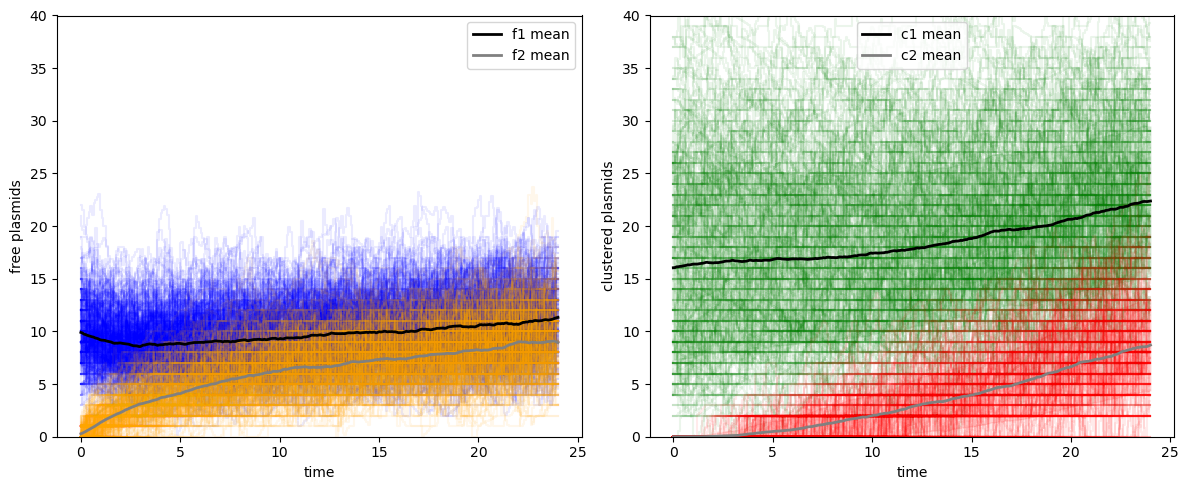

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# free plasmids: plot individuals faintly
for row in x1_mat:
    axes[0].step(t_grid, row, color='blue', alpha=0.08)
for row in x2_mat:
    axes[0].step(t_grid, row, color='orange', alpha=0.08)




axes[0].plot(t_grid, x1_mean, color='black', label='f1 mean', linewidth=2)
axes[0].fill_between(t_grid, x1_mean - x1_std, x1_mean + x1_std, alpha=0.1, color='blue')
axes[0].plot(t_grid, x2_mean, color='grey', label='f2 mean', linewidth=2)
axes[0].fill_between(t_grid, x2_mean - x2_std, x2_mean + x2_std, alpha=0.1, color='orange')
axes[0].set_ylim(0, 40)
axes[0].set_xlabel('time')
axes[0].set_ylabel('free plasmids')
axes[0].legend()

# clustered plasmids
for row in c1_mat:
    axes[1].step(t_grid, row, color='green', alpha=0.08)
for row in c2_mat:
    axes[1].step(t_grid, row, color='red', alpha=0.08)

#axes[1].plot(sol.t, sol.y[1], ls='--', label="c1 ODE", color = 'orange')
#axes[1].plot(sol.t, sol.y[3], ls='--', label="c2 ODE", color = 'green')


axes[1].plot(t_grid, c1_mean, color='black', label='c1 mean', linewidth=2)
axes[1].fill_between(t_grid, c1_mean - c1_std, c1_mean + c1_std, alpha=0.1, color='green')
axes[1].plot(t_grid, c2_mean, color='grey', label='c2 mean', linewidth=2)
axes[1].fill_between(t_grid, c2_mean - c2_std, c2_mean + c2_std, alpha=0.1, color='red')
axes[1].set_ylim(0, 40)
axes[1].set_xlabel('time')
axes[1].set_ylabel('clustered plasmids')
axes[1].legend()

plt.tight_layout()
plt.show()


Now plot all ODE systems including replication. Same plots as above. Use initial conditions that match Jayson's simulation - these are hard coded based on the mean initial values for f1, f2, c1, c2 in the above plot which shows trajectories for a 10th generation cell 

In [10]:
# Initial conditions
from scipy.integrate import solve_ivp
y0 = [9,14, 0, 0]  # f1, c1, f2, c2
N = y0[0]+y0[1]

# Time span
t_span = (0, 200)
t_eval = np.linspace(t_span[0], t_span[1], 10000)

# Solve ODE systems yes replication
solA_rep = solve_ivp(odeA_rep, t_span, y0, args=(beta, kappa, rho), t_eval=t_eval, method='BDF')
solB_rep = solve_ivp(odeB_rep, t_span, y0, args=(beta, kappa, rho), t_eval=t_eval, method='BDF')
solC_rep = solve_ivp(odeC_rep, t_span, y0, args=(beta, kappa, rho), t_eval=t_eval, method='BDF')
sol_lin_rep = solve_ivp(ode_lin_rep, t_span, y0, args=(beta, kappa, rho), t_eval=t_eval, method='BDF')

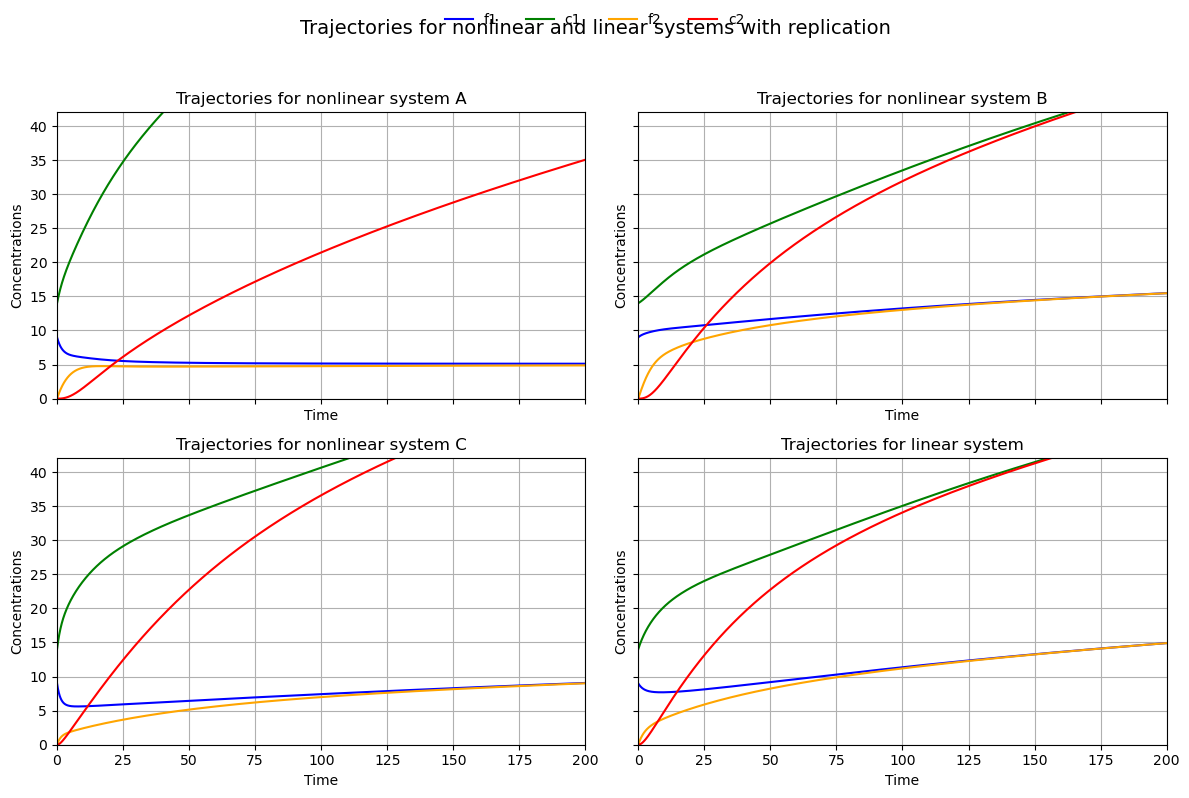

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
axes = axes.flatten()  # make it easier to iterate

systemsrep = [
    (solA_rep, "Trajectories for nonlinear system A"),
    (solB_rep, "Trajectories for nonlinear system B"),
    (solC_rep, "Trajectories for nonlinear system C"),
    (sol_lin_rep, "Trajectories for linear system"),
]

colors = ['blue', 'green', 'orange', 'red']
labels = ['f1', 'c1', 'f2', 'c2']

for ax, (sol, title) in zip(axes, systemsrep):
    for i, (label, color) in enumerate(zip(labels, colors)):
        ax.plot(sol.t, sol.y[i], label=label, color=color)
    ax.set_title(title)
    ax.set_xlabel("Time")
    ax.set_ylabel("Concentrations")
    ax.grid()
    ax.set_xlim(0, 200)
    ax.set_ylim(0, 42)

# Add one legend shared across subplots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False)

fig.suptitle("Trajectories for nonlinear and linear systems with replication", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])  # make room for the shared legend and title
plt.show()


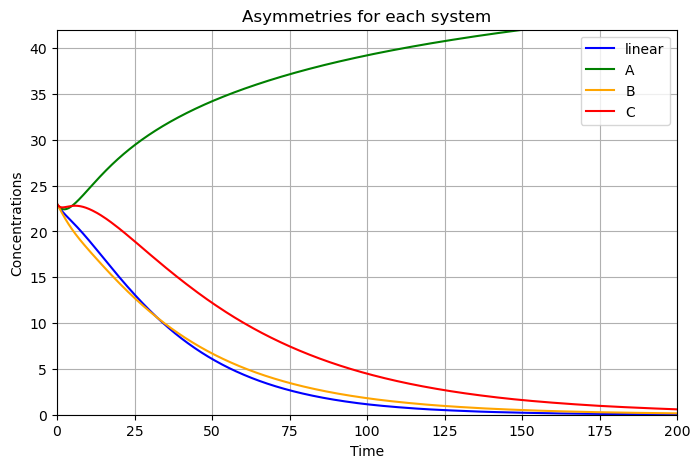

In [12]:
plt.figure(figsize=(8,5))
plt.plot(sol_lin_rep.t, (sol_lin_rep.y[0]+sol_lin_rep.y[1])-(sol_lin_rep.y[2]+sol_lin_rep.y[3]), label='linear', color='blue')
plt.plot(solA_rep.t, (solA_rep.y[0]+solA_rep.y[1])-(solA_rep.y[2]+solA_rep.y[3]), label='A', color='green')
plt.plot(solB_rep.t, (solB_rep.y[0]+solB_rep.y[1])-(solB_rep.y[2]+solB_rep.y[3]), label='B', color='orange')
plt.plot(solC_rep.t, (solC_rep.y[0]+solC_rep.y[1])-(solC_rep.y[2]+solC_rep.y[3]), label='C', color='red')

#plt.plot(solC_rep.t, 8*np.exp(-8/(21)*rho*solC_rep.t))


plt.xlabel("Time")
plt.ylabel("Concentrations")
plt.legend()
plt.title("Asymmetries for each system")
plt.grid()
plt.ylim(0,42)
plt.xlim(0,200)
plt.show()

Compare the asymmetry from the ODE models with replication to the asymmetry from Jayson's model. This was what I was thinking of for the supplementary figure in the paper - it shows that the asymmetry in the model that includes replication is similar to the simulations.

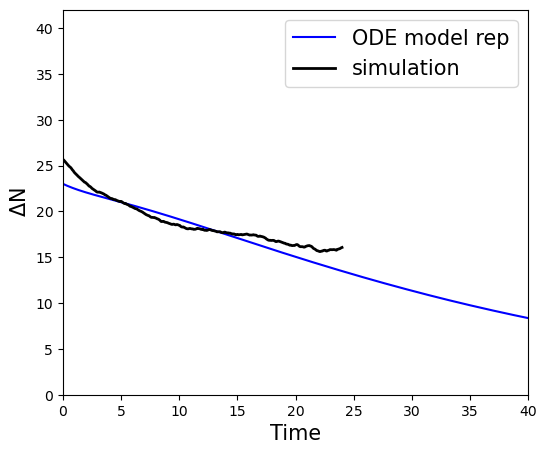

In [13]:
plt.figure(figsize=(6,5))

    plt.plot(sol_lin_rep.t, (sol_lin_rep.y[0]+sol_lin_rep.y[1])-(sol_lin_rep.y[2]+sol_lin_rep.y[3]), label='ODE model rep', color='blue')



plt.plot(t_grid, (x1_mean+c1_mean)-(x2_mean+c2_mean), color='black', label='simulation', linewidth=2)
plt.xlabel("Time", fontsize=15)
plt.ylabel("$\Delta$N", fontsize=15)
plt.legend(fontsize=15)
#plt.title("Asymmetries for models without replication")
plt.grid(False)
plt.ylim(0,42)
plt.xlim(0,40)
plt.show()



In [14]:
#t_grid = np.linspace(0, tau, 300)
np.savetxt('x1_mean'+str(tau)+'.csv', x1_mean, delimiter=",",header=" ")
np.savetxt('x2_mean'+str(tau)+'.csv', x2_mean, delimiter=",",header=" ")
np.savetxt('c1_mean'+str(tau)+'.csv', c1_mean, delimiter=",",header=" ")
np.savetxt('c2_mean'+str(tau)+'.csv', c2_mean, delimiter=",",header=" ")
np.savetxt('ode'+str(tau)+'.csv', sol_lin_rep.y, delimiter=",",header=" ")

x1_mean = pd.read_csv('x1_mean40.csv').values
x2_mean = pd.read_csv('x2_mean40.csv').values
c1_mean = pd.read_csv('c1_mean40.csv').values
c2_mean = pd.read_csv('c2_mean40.csv').values



    

In [15]:
np.savetxt('traj_mean'+str(tau)+'.csv', (x1_mean+c1_mean)-(x2_mean+c2_mean), delimiter=",",header=" ")